In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl
import tifffile
import random
import imageio.v3 as iio
from skophys.datasets import ARProcess, ARProcessMovie

%matplotlib inline

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [5]:
path = "/home/kushal/repos/td-svd-sandbox/M15D5_MC_rect-0.tif"

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
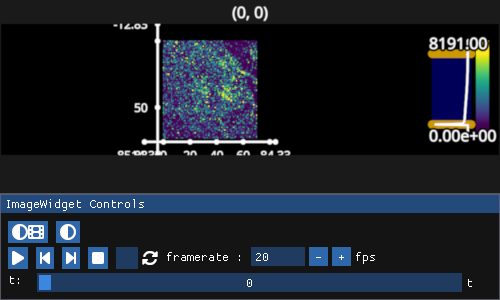

In [7]:
movie = tifffile.memmap(path)
fpl.ImageWidget(movie, cmap="viridis").show()

In [8]:
movie = movie[:, 10:60, :60]

In [13]:
from skimage.transform import downscale_local_mean

In [14]:
movie = downscale_local_mean(movie, (1, 2, 2))

In [15]:
movie_full = movie
movie.shape

(19999, 25, 30)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
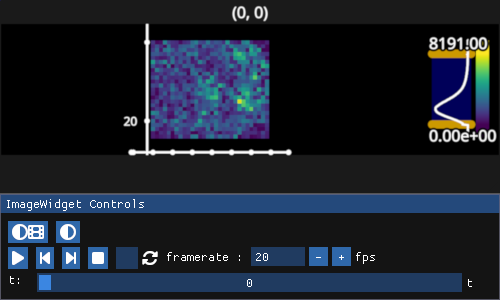

In [16]:
fpl.ImageWidget(movie, cmap="viridis").show()

In [17]:
from skophys.preprocessing import Vectorizer, UnVectorizer

/home/kushal/venvs/fpl/lib64/python3.12/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [18]:
X = Vectorizer().transform(movie)
unvec = UnVectorizer(movie.shape[1:])

X_full = Vectorizer().transform(movie_full)

In [19]:
from sklearn.preprocessing import StandardScaler

X_ = StandardScaler().fit_transform(X.T)

fpl.ImageWidget(X_.T, cmap="viridis").show()

X_zs = X_.T
X_zs.shape

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


(750, 19999)

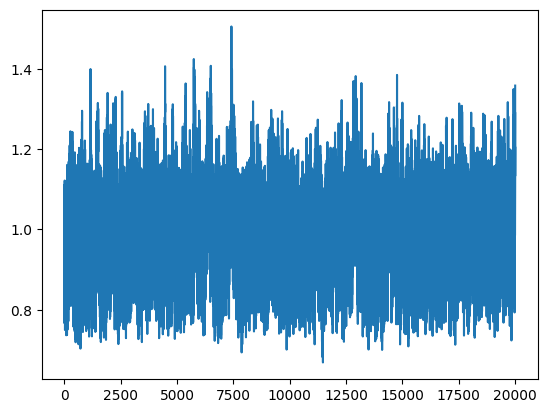

In [20]:
stds = X_zs.std(axis=0)
plt.plot(stds)

In [21]:
ixs = stds > 1.1

X.shape

ixs.sum()

X_full = X[:, ixs]
X = X_full
X.shape

(750, 3403)

In [22]:
X.shape

(750, 3403)

# k: number of components

In [23]:
k = 14

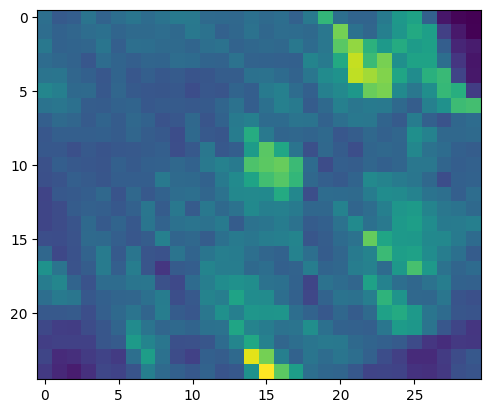

In [24]:
plt.imshow(movie.std(axis=0))

In [25]:
lag = 1
lag_step = 1
n_pixels = X.shape[0]

Hs = list()

for i in range(n_pixels):
    Hs.append(scipy.linalg.hankel(X[i, :lag * lag_step * 2], X[i, (lag * lag_step * 2) - 1:])[::lag_step])

H = np.zeros((lag * 2 * n_pixels, X.shape[1] - (lag * lag_step * 2) + 1))
for i, H_i in enumerate(Hs):
    H[i::n_pixels] = H_i


Hs = list()

for i in range(n_pixels):
    Hs.append(scipy.linalg.hankel(X_full[i, :lag * lag_step * 2], X_full[i, (lag * lag_step * 2) - 1:])[::lag_step])

H_full = np.zeros((lag * 2 * n_pixels, X_full.shape[1] - (lag * lag_step * 2) + 1))
for i, H_i in enumerate(Hs):
    H_full[i::n_pixels] = H_i

In [26]:
H.shape, H_full.shape

((1500, 3402), (1500, 3402))

In [27]:
mu0 = H[:lag * n_pixels].mean(axis=1)
mu1 = H[lag * n_pixels:].mean(axis=1)

H[:lag * n_pixels] -= mu0[:, None]
H[lag * n_pixels:] -= mu1[:, None]

past = H[:lag * n_pixels]
future = H[lag * n_pixels:]

mu0 = H_full[:lag * n_pixels].mean(axis=1)
mu1 = H_full[lag * n_pixels:].mean(axis=1)

H_full[:lag * n_pixels] -= mu0[:, None]
H_full[lag * n_pixels:] -= mu1[:, None]

past_full = H_full[:lag * n_pixels]
future_full = H_full[lag * n_pixels:]

In [28]:
H_nw = np.vstack(
    [
        past,
        future,
    ]
)

H = np.vstack(
    [
        scipy.linalg.pinv(scipy.linalg.sqrtm(past @ past.T / past.shape[1])) @ past,
        scipy.linalg.pinv(scipy.linalg.sqrtm(future @ future.T / future.shape[1])) @ future,
    ]
)

H_full = np.vstack(
    [
        scipy.linalg.pinv(scipy.linalg.sqrtm(past_full @ past_full.T / past_full.shape[1])) @ past_full,
        scipy.linalg.pinv(scipy.linalg.sqrtm(future_full @ future_full.T / future_full.shape[1])) @ future_full,
    ]
)

In [29]:
X_init = H

In [30]:
cov = X_init.T @ X_init

XTX = cov / np.linalg.norm(cov, ord="fro")

T = XTX.shape[0]

In [31]:
eta = 1.5

In [32]:
from tqdm.notebook import tqdm

In [33]:
movie.shape

(19999, 25, 30)

In [84]:
u, s, v = np.linalg.svd(H_nw)

[]

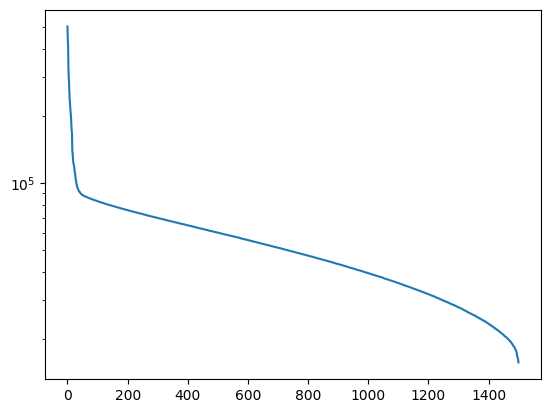

In [86]:
plt.plot(s)
plt.semilogy()

In [87]:
S_PTP = s

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


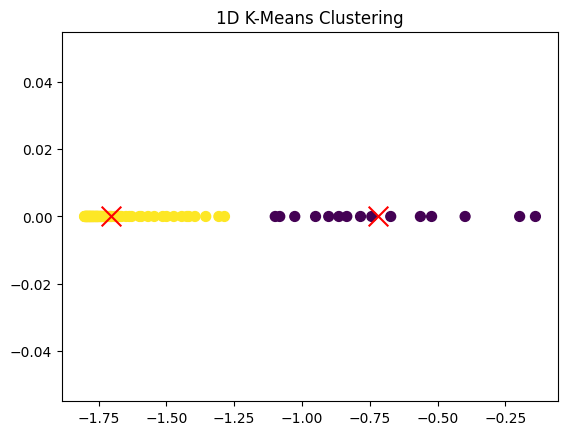

In [89]:
def kmeans_1d(data, k, max_iters=100, tol=1e-4):
    # Randomly initialize k cluster centers
    centroids = np.random.choice(data, k, replace=False)
    centroids[0] = np.max(data)
    for entry in range(1,k):
        centroids[entry] = np.min(data)

    for _ in range(max_iters):
        # Assign each point to the nearest centroid
        distances = np.abs(data[:, np.newaxis] - centroids[np.newaxis, :])
        labels = np.argmin(distances, axis=1)

        # Compute new centroids
        new_centroids = np.array([data[labels == i].mean() if np.any(labels == i) else centroids[i] 
                                  for i in range(k)])

        # Check for convergence
        if np.all(np.abs(new_centroids - centroids) < tol):
            break

        centroids = new_centroids

    return labels, centroids

max_entries = 100
# labels, centroids = kmeans_1d((S[1:max_entries] / S.max()), k=2)
labels, centroids = kmeans_1d(np.log(S_PTP[1:max_entries] / S_PTP.max()), k=2)
print (labels)

# Plotting
plt.scatter(np.log(S_PTP[1:max_entries] / S_PTP.max()), np.zeros_like(S_PTP[1:max_entries]), c=labels, cmap='viridis', s=50)
plt.scatter(centroids, np.zeros_like(centroids), color='red', marker='x', s=200)
plt.title('1D K-Means Clustering')
plt.show()

n_sources_kmeans = np.sum(labels == 0) + 1

In [90]:
n_sources_kmeans

16

In [91]:
k = n_sources_kmeans

In [92]:
def eco_whitened_matrix(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=False)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (k, num_extra_cols)
    num_extra_cols = X.shape[0] - k
    zeros = np.zeros((k, num_extra_cols))
    
    inv_S_reshape = np.hstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")

    # whitening matrix W shape (N, N)
    W = inv_S_reshape @ U.T

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = W @ X

    return Xw

In [95]:
Y = eco_whitened_matrix(H_nw, H_nw, k=k).clip(0)

X.shape = (1500, 3402)
inv_S.shape = (16, 16)
inv_S_reshape.shape = (16, 1500)
W.shape = (16, 1500)


<Axes: >

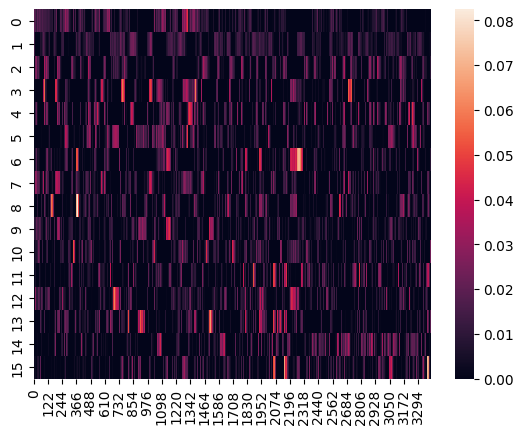

In [96]:
sns.heatmap(Y)

In [97]:
# Y /= Y.max()
# Y *= X.max()

error_log = list()

Ys = list()
Ws = list()

for iteration in tqdm(range(2000)):
    Ys.append(Y)
    Ws.append(Y @ X_init.T)

    if iteration > 500:
        eta = 1.0
    if iteration > 1_000:
        eta = 0.5
    
    Y_old = Y
    Y = Y + eta * Y @ (XTX - Y.T @ Y)

    # zeroed = Y.sum(axis=1) == 0.0
    # Y[zeroed] = (np.random.randn(zeroed.sum(), T) / np.sqrt(T)).clip(0)
    
    Y = Y.clip(0)

    er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta
    error_log.append(er)
    if er < 1e-3:
        break

  0%|          | 0/2000 [00:00<?, ?it/s]

In [98]:
er

0.0016957380262450775

[]

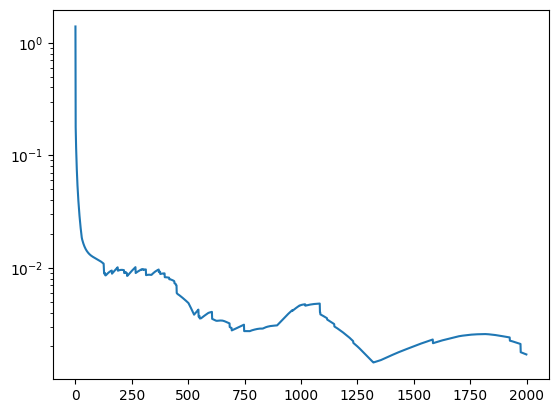

In [99]:
plt.plot(error_log)
plt.semilogy()

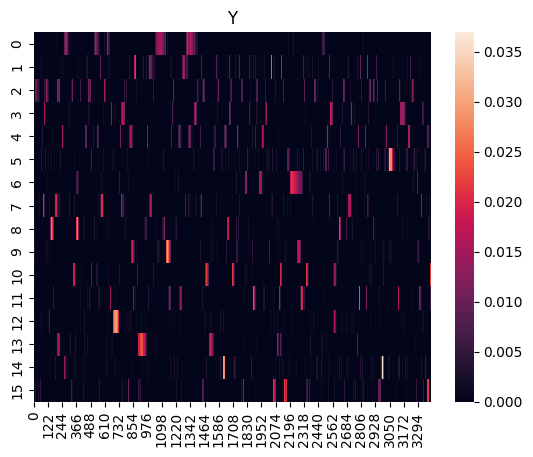

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
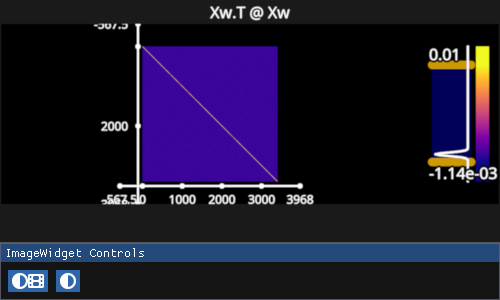

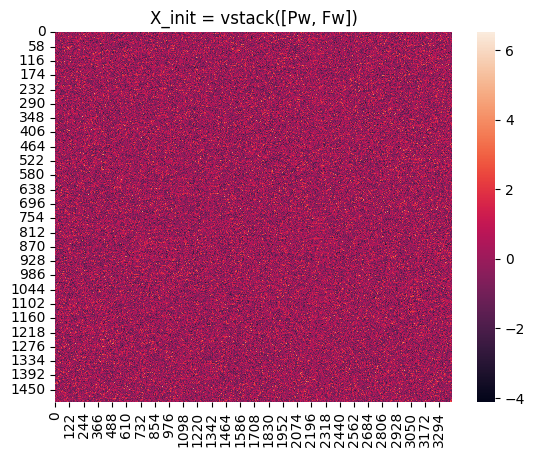

In [100]:
sns.heatmap(Y)
plt.title("Y")
plt.show()

iw_xtx = fpl.ImageWidget(XTX, names=["Xw.T @ Xw"], figure_kwargs={"show_tooltips": True})

display(iw_xtx.show())

sns.heatmap(X_init)
plt.title("X_init = vstack([Pw, Fw])")
plt.show()

In [101]:
W = Y @ X_init.T #/ sum_y_squared
W_nw = Y @ H_nw.T #/ sum_y_squared
M = Y @ Y.T #/ sum_y_squared

In [102]:
W.shape

(16, 1500)

In [103]:
Y.shape

(16, 3402)

<Axes: >

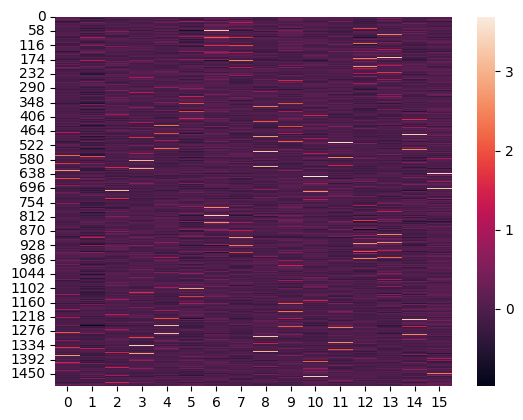

In [104]:
sns.heatmap(W.T)

<Axes: >

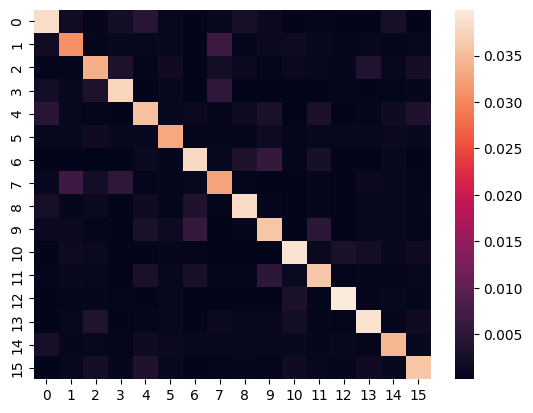

In [105]:
sns.heatmap(M)

In [106]:
M

array([[0.03844609, 0.00196323, 0.00056045, 0.00201588, 0.00443814,
        0.00083299, 0.00034802, 0.0009537 , 0.00250114, 0.00121752,
        0.00040137, 0.00048462, 0.00036345, 0.00029948, 0.0025727 ,
        0.00029799],
       [0.00196323, 0.03087361, 0.00065533, 0.00100315, 0.00082313,
        0.00098195, 0.00038761, 0.00650838, 0.00071692, 0.00125917,
        0.00149891, 0.00099778, 0.00055124, 0.00090082, 0.00062294,
        0.00078332],
       [0.00056045, 0.00065533, 0.03374937, 0.00321343, 0.00054341,
        0.00175387, 0.00026225, 0.00215006, 0.00138814, 0.00052389,
        0.00112625, 0.00085743, 0.00067078, 0.00371618, 0.00083624,
        0.00240819],
       [0.00201588, 0.00100315, 0.00321343, 0.03773521, 0.00014754,
        0.00104665, 0.00022823, 0.00507436, 0.00025291, 0.00028801,
        0.00025813, 0.00045101, 0.00050842, 0.00033474, 0.00056252,
        0.00066769],
       [0.00443814, 0.00082313, 0.00054341, 0.00014754, 0.03546674,
        0.00094423, 0.00137787, 

In [107]:
np.linalg.eigvals(M)

array([0.05443429, 0.02436591, 0.04438717, 0.04232056, 0.04028032,
       0.03947352, 0.03823419, 0.02966662, 0.02984447, 0.03037386,
       0.03629269, 0.03577246, 0.03229372, 0.03322008, 0.03381477,
       0.03421746])

In [108]:
from itertools import product

In [109]:
from ipywidgets import HBox, VBox

In [110]:
lag_slices = [slice(n_pixels * i, (i + 1) * n_pixels) for i in range(lag * 2)]
lag_slices

[slice(0, 750, None), slice(750, 1500, None)]

In [111]:
l_i = 0

In [112]:
# make images by reshaing each lag within `W`
images, titles = list(), list(),
for k_i, l_i in product(range(k), range(lag)):
    images.append(unvec.transform(W[k_i, lag_slices[l_i]].T))
    titles.append(f"k_{k_i}, l_{l_i}")

iw_W = fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    # figure_shape=(k, lag),
    figure_kwargs={"size": (800, 1000)},
)

for g in iw_W.managed_graphics:
    g.vmin = 0

images_nw = list()
for k_i, l_i in product(range(k), range(lag)):
    images_nw.append(unvec.transform(W_nw[k_i, lag_slices[l_i]].T))

iw_W_nw = fpl.ImageWidget(
    images_nw,
    cmap="viridis",
    names=titles,
    # figure_shape=(k, lag),
    figure_kwargs={"size": (800, 1000)},
)

for g in iw_W_nw.managed_graphics:
    g.vmin = 0

HBox([iw_W.show(), iw_W_nw.show()])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [113]:
Ws[0].shape

(16, 1500)

In [114]:
np.dstack(Ws).T.shape

(2000, 1500, 16)

In [115]:
np.dstack(Ws).shape

(16, 1500, 2000)

In [116]:
np.dstack(Ws)[:, :n_pixels].shape

(16, 750, 2000)

In [117]:
iw_Ws = fpl.ImageWidget(
    [unvec.transform(np.dstack(Ws)[i, :n_pixels]) for i in range(k)],
    cmap="viridis",
    figure_kwargs={"size": (1000, 500)},
    histogram_widget=False,
)

fig_error = fpl.Figure()
lg = fig_error[0, 0].add_line(np.log10(np.array(error_log) + 1))
sel = lg.add_linear_selector()

@sel.add_event_handler("selection")
def update_index(ev):
    i = ev.get_selected_index()
    iw_Ws.current_index = {"t": i}

VBox([iw_Ws.show(), fig_error.show(maintain_aspect=False)])

RFBOutputContext()

RFBOutputContext()

In [118]:
iw_Ys = fpl.ImageWidget(
    np.dstack(Ys).transpose(-1, 0, 1),
    cmap="viridis",
    figure_kwargs={"size": (1000, 500)},
)
iw_Ys.show(maintain_aspect=False)

fig_error = fpl.Figure()
lg = fig_error[0, 0].add_line(np.log10(np.array(error_log) + 1))
sel = lg.add_linear_selector()

@sel.add_event_handler("selection")
def update_index(ev):
    i = ev.get_selected_index()
    iw_Ys.current_index = {"t": i}

VBox([iw_Ys.show(), fig_error.show(maintain_aspect=False)])

RFBOutputContext()

RFBOutputContext()

Understand the overlap resolving in terms of covariance.

Comparison with non-PF similarity matching, pixels share covariance, cannot be resolved.
 --> Whiten the original data for this comparision too.

Even better initialization

Better tricks for initializing only using frames that contain events.